# Moduł 2.2 - trening FBCSP + LDA (LOSO)

**Literatura:**
- Ang i in. (2008), *Filter Bank Common Spatial Pattern (FBCSP) in Brain-Computer Interface*, IEEE IJCNN, [PDF](https://personal.ntu.edu.sg/ctguan/Publications/C_2008_KaiKeng_IEEE_IJCNN.pdf).
- Ang i in. (2012), *Filter Bank Common Spatial Pattern Algorithm on BCI Competition IV Datasets 2a and 2b*, *Frontiers in Neuroscience* 6:39, [DOI:10.3389/fnins.2012.00039](https://doi.org/10.3389/fnins.2012.00039).
- **Inna rodzina metod:** Barachant i in. (2012) opisują MDRM i TSLDA w geometrii riemannowskiej, a Congedo i in. (2017) przegląd tej dziedziny. Nie stanowią źródła implementacji FBCSP.


In [ ]:
from pathlib import Path
from functools import partial
import hashlib
import json
import os
import platform

import joblib
import matplotlib.pyplot as plt
import mne
mne.set_log_level("WARNING") 
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from scipy.signal import cheby2, sosfiltfilt
from IPython.display import display
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer

# ===== KONFIGURACJA MODELU =====
DATA_BASE = Path.cwd() / "dane_eegmmidb"
MANIFEST_PATH = None  # None -> ostatni zestaw z modułu 1
RESULTS_BASE = Path.cwd() / "wyniki_modeli" / "FBCSP_LDA"

# Dostępne częstotliwości zależą od filtracji z modułu 1 (domyślnie 8–30 Hz).
FBCSP_BANDS = [(8, 12), (12, 16), (16, 20), (20, 24), (24, 28), (28, 30)]
FILTER_ORDER = 4
FILTER_STOP_ATTENUATION_DB = 30 
N_CSP_PER_BAND = 4
N_SELECTED_FEATURES = 8
MI_RANDOM_STATE = 42

TUNE_THRESHOLD = False
DEFAULT_THRESHOLD = 0.50
MIN_VALIDATION_RECALL = 0.20
MIN_VALIDATION_POSITIVES = 3
REFIT_ON_ALL_NON_TEST = True
SAVE_MODELS = True
VERIFY_FILE_HASHES = True

# ===== PREZENTACJA WYNIKÓW PO TRENINGU =====
SHOW_PLOTS = True
SAVE_PLOTS = True
TEST_SUBJECT_TO_SHOW = None
N_SAMPLES = 10

assert FILTER_ORDER >= 1
assert FILTER_STOP_ATTENUATION_DB > 0
assert N_CSP_PER_BAND >= 2
assert 1 <= N_SELECTED_FEATURES <= N_CSP_PER_BAND * len(FBCSP_BANDS)
assert len(FBCSP_BANDS) == len(set(FBCSP_BANDS))
assert N_SAMPLES >= 1
assert 0 < DEFAULT_THRESHOLD < 1
assert 0 <= MIN_VALIDATION_RECALL <= 1
assert MIN_VALIDATION_POSITIVES >= 1
print("Python:", platform.python_version(), "| MNE:", mne.__version__,
      "| scikit-learn:", sklearn.__version__, "| SciPy:", scipy.__version__)


Python: 3.12.12 | MNE: 1.13.2 | scikit-learn: 1.9.1 | SciPy: 1.18.0


## 1. Odczyt danych z modułu 1 i kontrola zgodności

In [ ]:
def read_json(path):
    with Path(path).open(encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def stable_hash(payload, size=12):
    return hashlib.sha256(json.dumps(payload, sort_keys=True,
                                     ensure_ascii=False).encode("utf-8")).hexdigest()[:size]


if MANIFEST_PATH is None:
    pointer = read_json(DATA_BASE / "ostatni_zestaw.json")
    manifest_path = (DATA_BASE / pointer["manifest_relative_path"]).resolve()
else:
    manifest_path = Path(MANIFEST_PATH).expanduser().resolve()
manifest = read_json(manifest_path)
if manifest.get("schema_version") != "1.0":
    raise ValueError("Nieobsługiwana wersja struktury danych.")
dataset_dir = manifest_path.parent
for key, info in manifest["files"].items():
    path = dataset_dir / info["path"]
    if not path.is_file():
        raise FileNotFoundError(path)
    if VERIFY_FILE_HASHES and sha256_file(path) != info["sha256"]:
        raise ValueError(f"Niezgodny SHA-256 (zmieniony plik): {path}")

X_all = np.load(dataset_dir / manifest["files"]["X"]["path"], mmap_mode="r")
y_all = np.load(dataset_dir / manifest["files"]["y"]["path"], mmap_mode="r")
groups = np.load(dataset_dir / manifest["files"]["groups"]["path"], mmap_mode="r")
epoch_run = np.load(dataset_dir / manifest["files"]["runs"]["path"], mmap_mode="r")
splits = read_json(dataset_dir / manifest["files"]["splits"]["path"])
SUBJECT_IDS = [int(s) for s in manifest["subject_ids"]]
CLASS_NAMES = {int(k): v for k, v in manifest["labels"].items()}
POSITIVE_LABEL = int(manifest["positive_label"])

if X_all.dtype != np.float32 or X_all.ndim != 3 or list(X_all.shape) != manifest["X_shape"]:
    raise ValueError("Niezgodny format X: spodziewano się float32 i [epoki,kanały,próbki].")
if not (len(X_all) == len(y_all) == len(groups) == len(epoch_run)):
    raise ValueError("Liczby epok w plikach różnią się.")
if y_all.dtype != np.int8 or groups.dtype != np.int16 or epoch_run.dtype != np.int8:
    raise ValueError("Niezgodne typy y/groups/runs.")
if np.unique(groups).tolist() != SUBJECT_IDS or set(np.unique(y_all)) != {1, 2}:
    raise ValueError("Niezgodne identyfikatory/etykiety uczestników.")
if POSITIVE_LABEL != 2 or N_CSP_PER_BAND > X_all.shape[1] - 1:
    raise ValueError("T2 musi mieć etykietę 2, a N_CSP_PER_BAND <= (liczba kanałów - 1) przy average reference.")
if splits["dataset_id"] != manifest["dataset_id"]:
    raise ValueError("Podziały LOSO pochodzą z innego zestawu.")
if [f["test_subject"] for f in splits["folds"]] != SUBJECT_IDS:
    raise ValueError("Podziały LOSO nie obejmują dokładnie wszystkich wybranych osób.")
for fold in splits["folds"]:
    a, b, c = (set(fold[k]) for k in
               ("train_subjects_internal", "validation_subjects", "test_subjects"))
    if a & b or a & c or b & c or a | b | c != set(SUBJECT_IDS):
        raise ValueError(f"Nieszczelny/niekompletny split LOSO: {fold['fold']}")
    if c != {fold["test_subject"]}:
        raise ValueError("Split zawiera nieprawidłową osobę testową.")

print("Zestaw:", manifest["dataset_id"], "| X:", X_all.shape, "| osób:", len(SUBJECT_IDS))
print("Klasy:", CLASS_NAMES, "| rodzaje zadań:", manifest["task_types"])
print("Protokół LOSO:", len(splits["folds"]), "foldów, seed:", splits["seed"])

SFREQ = float(manifest["preprocessing"]["target_sfreq"])
INPUT_FMIN = float(manifest["preprocessing"]["fmin"])
INPUT_FMAX = float(manifest["preprocessing"]["fmax"])
if not 0 < INPUT_FMIN < INPUT_FMAX < SFREQ / 2:
    raise ValueError("Manifest zawiera niepoprawny zakres pasma wejściowego.")
for low, high in FBCSP_BANDS:
    if not INPUT_FMIN <= low < high <= INPUT_FMAX:
        raise ValueError(f"Pasmo {low}-{high} Hz wykracza poza {INPUT_FMIN}-{INPUT_FMAX} Hz w module 1.")
if X_all.shape[2] < 40:
    raise ValueError("Zbyt krótka epoka do filtracji bankowej.")
print("Pasmo dostępne z modułu 1:", (INPUT_FMIN, INPUT_FMAX), "Hz")
print("Pasma FBCSP:", FBCSP_BANDS, "| liczba cech przed selekcją:",
      len(FBCSP_BANDS) * N_CSP_PER_BAND, "| po selekcji:", N_SELECTED_FEATURES)


Zestaw: 0a8da1dbe454 | X: (9844, 64, 321) | osób: 109
Klasy: {1: 'lewa dłoń', 2: 'prawa dłoń'} | rodzaje zadań: ['motor_execution', 'motor_imagery']
Protokół LOSO: 109 foldów, seed: 42
Pasmo dostępne z modułu 1: (8.0, 30.0) Hz
Pasma FBCSP: [(8, 12), (12, 16), (16, 20), (20, 24), (24, 28), (28, 30)] | liczba cech przed selekcją: 24 | po selekcji: 8


## 2. Model FBCSP + LDA - filtracja, przestrzenne CSP, MIBIF i klasyfikator

In [ ]:
def make_model():
    # Konwersja z float32 na float64 następuje na wejściu
    branches = []
    for low, high in FBCSP_BANDS:
        sos = cheby2(
            FILTER_ORDER, FILTER_STOP_ATTENUATION_DB,
            [float(low), float(high)], btype="bandpass", fs=SFREQ,
            output="sos",
        )
        band_model = Pipeline([
            ("BandFilter", FunctionTransformer(
                partial(sosfiltfilt, sos, axis=-1), validate=False,
            )),
            ("CSP", CSP(
                n_components=N_CSP_PER_BAND, reg=None, log=True,
                norm_trace=False, cov_est="concat",
                rank={"eeg": X_all.shape[1] - 1},
            )),
        ])
        branches.append((f"band_{low:g}_{high:g}Hz", band_model))

    return Pipeline([
        ("ToFloat64", FunctionTransformer(
            np.asarray, validate=False, kw_args={"dtype": np.float64},
        )),
        ("FBCSP", FeatureUnion(transformer_list=branches, n_jobs=1)),
        ("MIBIF", SelectKBest(
            score_func=partial(mutual_info_classif, random_state=MI_RANDOM_STATE),
            k=N_SELECTED_FEATURES,
        )),
        ("LDA", LinearDiscriminantAnalysis()),
    ])


def selected_feature_rows(model, fold_no, test_subject):
    """Zwraca wybrane CECHY treningowe (bez użycia etykiet testowych)."""
    selector = model.named_steps["MIBIF"]
    kept = selector.get_support(indices=True)
    rows = []
    for rank, feature_idx in enumerate(kept, start=1):
        band_idx, csp_component = divmod(int(feature_idx), N_CSP_PER_BAND)
        low, high = FBCSP_BANDS[band_idx]
        rows.append({
            "fold": int(fold_no), "test_subject": int(test_subject),
            "selected_feature_order": rank,
            "feature_index": int(feature_idx),
            "band_low_hz": float(low), "band_high_hz": float(high),
            "csp_component_zero_based": int(csp_component),
            "mutual_information": float(selector.scores_[feature_idx]),
        })
    return rows


def positive_probabilities(model, X):
    classes = model.classes_
    if POSITIVE_LABEL not in classes:
        raise ValueError("Brak klasy dodatniej w wytrenowanym modelu.")
    column = int(np.flatnonzero(classes == POSITIVE_LABEL)[0])
    return model.predict_proba(X)[:, column]


def labels_from_probability(prob, threshold):
    return np.where(prob >= threshold, POSITIVE_LABEL, 1).astype(np.int8)


def choose_validation_threshold(y_true, prob):
    def scores(threshold):
        pred = labels_from_probability(prob, threshold)
        return (float(precision_score(y_true, pred, pos_label=2, zero_division=0)),
                float(recall_score(y_true, pred, pos_label=2, zero_division=0)))

    if not TUNE_THRESHOLD:
        p, r = scores(DEFAULT_THRESHOLD)
        return float(DEFAULT_THRESHOLD), "fixed", p, r
    candidates = []
    for threshold in np.linspace(0.05, 0.95, 91):
        predicted = labels_from_probability(prob, threshold)
        n_positive = int((predicted == POSITIVE_LABEL).sum())
        p, r = scores(threshold)
        if r >= MIN_VALIDATION_RECALL and n_positive >= MIN_VALIDATION_POSITIVES:
            candidates.append((p, r, -abs(threshold - 0.5), float(threshold)))
    if not candidates:
        p, r = scores(DEFAULT_THRESHOLD)
        return float(DEFAULT_THRESHOLD), "fallback_0.5", p, r
    p, r, _, threshold = max(candidates)
    return threshold, "validation_optimized", p, r


def calculate_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[1, 2]).ravel()
    return {
        "precision_T2": float(precision_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "recall_T2": float(recall_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "f1_T2": float(f1_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "n_test_epochs": int(len(y_true)),
        "n_predicted_T2": int((y_pred == 2).sum()),
    }


## 3. Rejestracja eksperymentu i niezależne pliki wynikowe

In [4]:
TRAIN_CONFIG = {
    "model": "FBCSP_LDA", "dataset_id": manifest["dataset_id"],
    "bands_hz": [list(pair) for pair in FBCSP_BANDS],
    "filter_type": "cheby2_sos", "filter_order": FILTER_ORDER,
    "filter_stop_attenuation_db": FILTER_STOP_ATTENUATION_DB,
    "filter_zero_phase": True, "filter_on_already_epoched_data": True,
    "n_csp_per_band": N_CSP_PER_BAND,
    "csp_reg": None, "csp_log": True, "csp_norm_trace": False,
    "csp_cov_est": "concat", "csp_rank": X_all.shape[1] - 1,
    "feature_selection": "MIBIF_select_k_best_mutual_info_classif",
    "n_selected_features": N_SELECTED_FEATURES,
    "mutual_information_random_state": MI_RANDOM_STATE,
    "tune_threshold": TUNE_THRESHOLD, "default_threshold": DEFAULT_THRESHOLD,
    "min_validation_recall": MIN_VALIDATION_RECALL,
    "min_validation_positives": MIN_VALIDATION_POSITIVES,
    "refit_on_all_non_test": REFIT_ON_ALL_NON_TEST,
    "positive_label": POSITIVE_LABEL, "save_models": SAVE_MODELS,
    "versions": {"python": platform.python_version(), "mne": mne.__version__,
                 "sklearn": sklearn.__version__, "numpy": np.__version__,
                 "scipy": scipy.__version__},
}
TRAIN_HASH = stable_hash(TRAIN_CONFIG)
OUTPUT_DIR = RESULTS_BASE / manifest["dataset_id"] / TRAIN_HASH
MODEL_DIR = OUTPUT_DIR / "modele"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_MODELS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
experiment_manifest = {
    "experiment_id": TRAIN_HASH, "model": "FBCSP_LDA",
    "dataset_id": manifest["dataset_id"],
    "data_manifest_relative_path": os.path.relpath(manifest_path, OUTPUT_DIR),
    "config": TRAIN_CONFIG, "n_folds_expected": len(SUBJECT_IDS),
    "model_file_pattern": "modele/S{subject:03d}.joblib" if SAVE_MODELS else None,
    "results": {"per_subject": "wyniki_per_subject.csv",
                "predictions": "predykcje_epok.csv",
                "assignments": "podzialy_uczestnikow.csv",
                "selected_features": "wybrane_cechy_fbcsp.csv"},
}
with (OUTPUT_DIR / "manifest_modelu.json").open("w", encoding="utf-8") as f:
    json.dump(experiment_manifest, f, indent=2, ensure_ascii=False)

print("Wyniki eksperymentu:", OUTPUT_DIR)
print("Modele na dysku:", SAVE_MODELS)


Wyniki eksperymentu: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/FBCSP_LDA/0a8da1dbe454/9ef2022ff767
Modele na dysku: True


## 4. Główna pętla LOSO - identyczne foldy jak CSP + LDA

In [ ]:
fold_results, fold_assignments, predictions, selected_features = [], [], [], []
for fold in splits["folds"]:
    fold_no = int(fold["fold"])
    test_subject = int(fold["test_subject"])
    train_people = fold["train_subjects_internal"]
    val_people = fold["validation_subjects"]

    train_idx = np.flatnonzero(np.isin(groups, train_people))
    val_idx = np.flatnonzero(np.isin(groups, val_people))
    test_idx = np.flatnonzero(groups == test_subject)
    non_test_idx = np.flatnonzero(groups != test_subject)
    if len(train_idx) + len(val_idx) + len(test_idx) != len(groups):
        raise AssertionError(f"Fold {fold_no}: niepełny podział epok")
    if any(set(np.unique(y_all[ix])) != {1, 2} for ix in (train_idx, val_idx, test_idx)):
        raise ValueError(f"Fold {fold_no}: brak obu klas w jednym z podziałów")

    validation_model = make_model()
    validation_model.fit(X_all[train_idx], y_all[train_idx])
    validation_prob = positive_probabilities(validation_model, X_all[val_idx])
    threshold, method, val_precision, val_recall = choose_validation_threshold(
        y_all[val_idx], validation_prob
    )

    if REFIT_ON_ALL_NON_TEST:
        final_model = make_model()
        final_model.fit(X_all[non_test_idx], y_all[non_test_idx])
    else:
        final_model = validation_model

    test_prob = positive_probabilities(final_model, X_all[test_idx])
    test_pred = labels_from_probability(test_prob, threshold)
    metrics = calculate_metrics(y_all[test_idx], test_pred)
    selected_features.extend(selected_feature_rows(final_model, fold_no, test_subject))

    if SAVE_MODELS:
        joblib.dump(final_model, MODEL_DIR / f"S{test_subject:03d}.joblib", compress=3)

    fold_results.append({
        "fold": fold_no, "test_subject": test_subject,
        "dataset_id": manifest["dataset_id"],
        "n_train_subjects_internal": len(train_people),
        "n_validation_subjects": len(val_people),
        "n_train_subjects_final": len(SUBJECT_IDS) - 1
            if REFIT_ON_ALL_NON_TEST else len(train_people),
        "n_train_epochs_internal": int(len(train_idx)),
        "n_validation_epochs": int(len(val_idx)),
        "threshold_T2": threshold, "threshold_method": method,
        "validation_precision_T2": val_precision,
        "validation_recall_T2": val_recall,
        **metrics,
    })
    fold_assignments.append({
        "fold": fold_no, "test_subject": test_subject,
        "train_subjects_internal": ",".join(map(str, train_people)),
        "validation_subjects": ",".join(map(str, val_people)),
        "test_subjects": str(test_subject),
        "final_train_subjects": ",".join(
            map(str, [s for s in SUBJECT_IDS if s != test_subject]
                if REFIT_ON_ALL_NON_TEST else train_people)
        ),
    })
    for test_epoch, (global_index, pred, prob) in enumerate(
        zip(test_idx, test_pred, test_prob), start=1
    ):
        predictions.append({
            "fold": fold_no, "test_subject": test_subject,
            "test_epoch": test_epoch, "global_epoch_index": int(global_index),
            "run": int(epoch_run[global_index]),
            "y_true": int(y_all[global_index]), "y_pred": int(pred),
            "probability_T2": float(prob), "threshold_T2": float(threshold),
        })

    pd.DataFrame(fold_results).to_csv(OUTPUT_DIR / "wyniki_per_subject.csv", index=False)
    pd.DataFrame(fold_assignments).to_csv(
        OUTPUT_DIR / "podzialy_uczestnikow.csv", index=False
    )
    pd.DataFrame(predictions).to_csv(OUTPUT_DIR / "predykcje_epok.csv", index=False)
    pd.DataFrame(selected_features).to_csv(OUTPUT_DIR / "wybrane_cechy_fbcsp.csv", index=False)

    print(f"[{fold_no:03d}/{len(SUBJECT_IDS):03d}] test S{test_subject:03d} | "
          f"precision T2={metrics['precision_T2']:.3f} | "
          f"recall T2={metrics['recall_T2']:.3f} | "
          f"balanced accuracy={metrics['balanced_accuracy']:.3f}")

results_df = pd.DataFrame(fold_results)
predictions_df = pd.DataFrame(predictions)
selected_features_df = pd.DataFrame(selected_features)
assert results_df["test_subject"].tolist() == SUBJECT_IDS
assert len(predictions_df) == len(X_all)
assert len(selected_features_df) == len(SUBJECT_IDS) * N_SELECTED_FEATURES
assert set(predictions_df["global_epoch_index"]) == set(range(len(X_all)))

RESULTS_BASE.mkdir(parents=True, exist_ok=True)
with (RESULTS_BASE / "ostatni_eksperyment.json").open("w", encoding="utf-8") as f:
    json.dump({"experiment_relative_path": str(OUTPUT_DIR.relative_to(RESULTS_BASE)),
               "dataset_id": manifest["dataset_id"],
               "experiment_id": TRAIN_HASH}, f, indent=2)
print("\nZakończono LOSO:", len(results_df), "osób,", len(predictions_df), "predykcji")
print("Wyniki i modele:", OUTPUT_DIR)


[001/109] test S001 | precision T2=0.500 | recall T2=0.727 | balanced accuracy=0.516
[002/109] test S002 | precision T2=0.562 | recall T2=0.205 | balanced accuracy=0.526
[003/109] test S003 | precision T2=0.500 | recall T2=0.200 | balanced accuracy=0.500
[004/109] test S004 | precision T2=0.544 | recall T2=0.822 | balanced accuracy=0.567
[005/109] test S005 | precision T2=0.571 | recall T2=0.174 | balanced accuracy=0.519
[006/109] test S006 | precision T2=0.538 | recall T2=0.477 | balanced accuracy=0.543
[007/109] test S007 | precision T2=0.789 | recall T2=0.341 | balanced accuracy=0.627
[008/109] test S008 | precision T2=0.222 | recall T2=0.043 | balanced accuracy=0.442
[009/109] test S009 | precision T2=0.519 | recall T2=0.651 | balanced accuracy=0.549
[010/109] test S010 | precision T2=0.556 | recall T2=0.595 | balanced accuracy=0.589
[011/109] test S011 | precision T2=0.513 | recall T2=0.889 | balanced accuracy=0.522
[012/109] test S012 | precision T2=0.833 | recall T2=0.111 | bala

## 5. Wyniki treningu - tabela, przedział ufności i wykresy

Wyniki dla wszystkich uczestników testowych:


,test_subject,precision_T2,recall_T2,f1_T2,balanced_accuracy,accuracy,n_test_epochs,n_predicted_T2,threshold_T2
0,1,0.500,0.727,0.593,0.516,0.511,90,64,0.5
1,2,0.562,0.205,0.300,0.526,0.533,90,16,0.5
2,3,0.500,0.200,0.286,0.500,0.500,90,18,0.5
3,4,0.544,0.822,0.655,0.567,0.567,90,68,0.5
4,5,0.571,0.174,0.267,0.519,0.511,90,14,0.5
...,...,...,...,...,...,...,...,...,...
104,105,0.589,0.717,0.647,0.597,0.600,90,56,0.5
105,106,0.540,0.614,0.574,0.557,0.556,90,50,0.5
106,107,0.478,0.744,0.582,0.500,0.489,90,67,0.5
107,108,0.673,0.702,0.688,0.665,0.667,90,49,0.5


Podsumowanie LOSO (każda osoba ma równą wagę):


,metric,n_subjects,mean,std,CI95_lower,CI95_upper
0,precision_T2,109,0.549,0.121,0.526,0.572
1,recall_T2,109,0.566,0.261,0.517,0.616
2,f1_T2,109,0.520,0.164,0.489,0.551
3,balanced_accuracy,109,0.547,0.064,0.535,0.560
4,accuracy,109,0.547,0.065,0.535,0.559


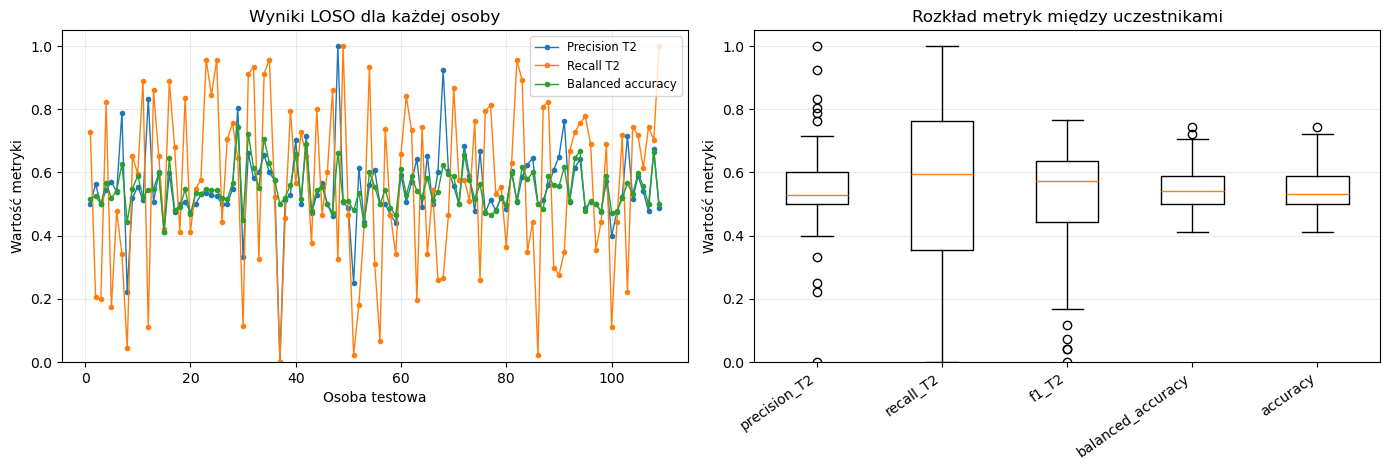

In [6]:
METRIC_COLS = ["precision_T2", "recall_T2", "f1_T2", "balanced_accuracy", "accuracy"]
summary_rows = []
for metric in METRIC_COLS:
    values = results_df[metric].to_numpy(dtype=float)
    n = len(values)
    mean = float(np.mean(values))
    sd = float(np.std(values, ddof=1)) if n > 1 else 0.0
    if n <= 1 or np.isclose(sd, 0.0):
        ci_low = ci_high = mean
    else:
        ci_low, ci_high = stats.t.interval(
            0.95, df=n - 1, loc=mean, scale=stats.sem(values)
        )
    summary_rows.append({
        "metric": metric, "n_subjects": n,
        "mean": mean, "std": sd,
        "CI95_lower": float(ci_low), "CI95_upper": float(ci_high),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUTPUT_DIR / "podsumowanie_loso.csv", index=False)

print("Wyniki dla wszystkich uczestników testowych:")
display(results_df[[
    "test_subject", "precision_T2", "recall_T2", "f1_T2",
    "balanced_accuracy", "accuracy", "n_test_epochs",
    "n_predicted_T2", "threshold_T2",
]].round(3))
print("Podsumowanie LOSO (każda osoba ma równą wagę):")
display(summary_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for metric, label in [
    ("precision_T2", "Precision T2"),
    ("recall_T2", "Recall T2"),
    ("balanced_accuracy", "Balanced accuracy"),
]:
    axes[0].plot(results_df["test_subject"], results_df[metric],
                 marker="o", markersize=3, linewidth=1.0, label=label)
axes[0].set(title="Wyniki LOSO dla każdej osoby", xlabel="Osoba testowa",
            ylabel="Wartość metryki", ylim=(0, 1.05))
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize="small")

axes[1].boxplot([results_df[metric].to_numpy() for metric in METRIC_COLS])
axes[1].set_xticks(range(1, len(METRIC_COLS) + 1))
axes[1].set_xticklabels(METRIC_COLS, rotation=35, ha="right")
axes[1].set(title="Rozkład metryk między uczestnikami", ylabel="Wartość metryki",
            ylim=(0, 1.05))
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "wyniki_loso.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)


## 6. Macierz pomyłek i raport klasyfikacji

Macierz pomyłek agreguje predykcje *po epokach* wszystkich testowych foldów LOSO; nie zastępuje raportu z metrykami uśrednionymi **po osobach**.


Raport klasyfikacji (agregacja po epokach):
              precision    recall  f1-score   support

   lewa dłoń       0.55      0.53      0.54      4950
  prawa dłoń       0.54      0.57      0.55      4894

    accuracy                           0.55      9844
   macro avg       0.55      0.55      0.55      9844
weighted avg       0.55      0.55      0.55      9844



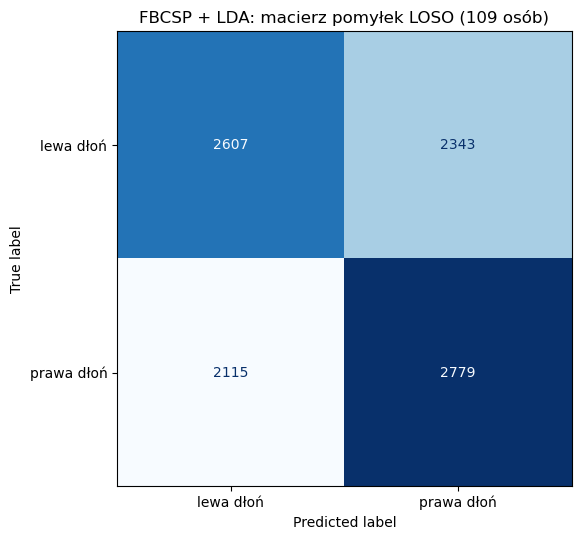

In [7]:
y_true_all = predictions_df["y_true"].to_numpy(dtype=np.int8)
y_pred_all = predictions_df["y_pred"].to_numpy(dtype=np.int8)
report_text = classification_report(
    y_true_all, y_pred_all, labels=[1, 2],
    target_names=[CLASS_NAMES[1], CLASS_NAMES[2]], zero_division=0,
)
print("Raport klasyfikacji (agregacja po epokach):")
print(report_text)
(OUTPUT_DIR / "raport_klasyfikacji.txt").write_text(report_text, encoding="utf-8")

cm = confusion_matrix(y_true_all, y_pred_all, labels=[1, 2])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[CLASS_NAMES[1], CLASS_NAMES[2]],
).plot(values_format="d", cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"FBCSP + LDA: macierz pomyłek LOSO ({len(SUBJECT_IDS)} osób)")
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "macierz_pomylek.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)


## 7. Przykładowe predykcje i pasma wybrane przez MIBIF

Przykładowe predykcje testowe S109: 10 z 90 epok


,test_epoch,run,prawda,predykcja,probability_T2,threshold_T2,poprawnie
0,1,3,lewa dłoń,prawa dłoń,0.939,0.5,False
1,2,3,prawa dłoń,prawa dłoń,0.923,0.5,True
2,3,3,lewa dłoń,prawa dłoń,0.905,0.5,False
3,4,3,prawa dłoń,prawa dłoń,0.938,0.5,True
4,5,3,prawa dłoń,prawa dłoń,0.951,0.5,True
5,6,3,lewa dłoń,prawa dłoń,0.921,0.5,False
6,7,3,lewa dłoń,prawa dłoń,0.932,0.5,False
7,8,3,prawa dłoń,prawa dłoń,0.907,0.5,True
8,9,3,lewa dłoń,prawa dłoń,0.943,0.5,False
9,10,3,prawa dłoń,prawa dłoń,0.886,0.5,True



Wybrane cechy FBCSP dla S109 (model trenowany bez tej osoby):


,band_low_hz,band_high_hz,csp_component_zero_based,mutual_information
868,16.0,20.0,3,0.0126
867,16.0,20.0,2,0.0101
864,8.0,12.0,2,0.0076
865,12.0,16.0,1,0.0070
869,20.0,24.0,0,0.0058
866,12.0,16.0,2,0.0052
871,24.0,28.0,0,0.0041
870,20.0,24.0,1,0.0040


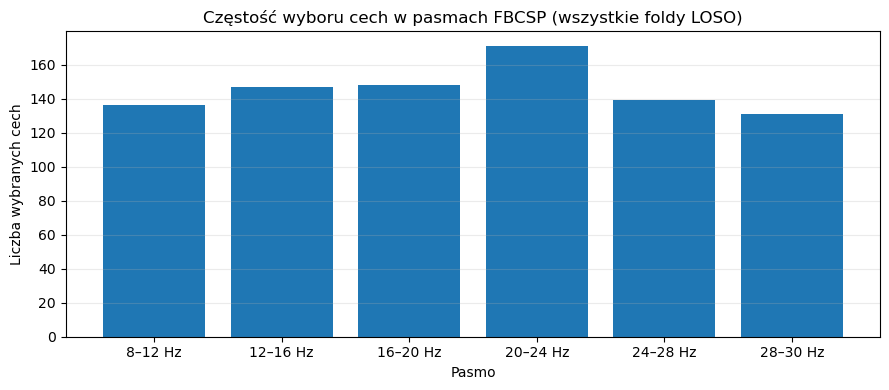


Zapisane wyniki eksperymentu: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/FBCSP_LDA/0a8da1dbe454/9ef2022ff767
- wyniki_per_subject.csv, predykcje_epok.csv, podzialy_uczestnikow.csv
- podsumowanie_loso.csv, raport_klasyfikacji.txt
- wybrane_cechy_fbcsp.csv
- wyniki_loso.png, macierz_pomylek.png, wybrane_pasma_fbcsp.png
- modele/Sxxx.joblib (osobny model dla każdego folda LOSO)


In [8]:
subject_to_show = (SUBJECT_IDS[-1] if TEST_SUBJECT_TO_SHOW is None
                   else int(TEST_SUBJECT_TO_SHOW))
if subject_to_show not in SUBJECT_IDS:
    raise ValueError(f"S{subject_to_show:03d} nie występuje w wynikach LOSO.")
chosen = (predictions_df[predictions_df["test_subject"] == subject_to_show]
          .sort_values("test_epoch").reset_index(drop=True))
print(f"Przykładowe predykcje testowe S{subject_to_show:03d}: "
      f"{min(N_SAMPLES, len(chosen))} z {len(chosen)} epok")
examples = chosen[[
    "test_epoch", "run", "y_true", "y_pred", "probability_T2", "threshold_T2",
]].head(N_SAMPLES).copy()
examples["prawda"] = examples["y_true"].map(CLASS_NAMES)
examples["predykcja"] = examples["y_pred"].map(CLASS_NAMES)
examples["poprawnie"] = examples["y_true"].eq(examples["y_pred"])
display(examples[[
    "test_epoch", "run", "prawda", "predykcja",
    "probability_T2", "threshold_T2", "poprawnie",
]].round(3))

print("\nWybrane cechy FBCSP dla S%03d (model trenowany bez tej osoby):" % subject_to_show)
display(selected_features_df[
    selected_features_df["test_subject"] == subject_to_show
][["band_low_hz", "band_high_hz", "csp_component_zero_based",
   "mutual_information"]].sort_values("mutual_information", ascending=False).round(4))

# Dodatkowy wykres — ile razy konkretne pasmo wystąpiło w wybranych cechach.
selected_bands_count = (
    selected_features_df.groupby(["band_low_hz", "band_high_hz"])
    .size().rename("n_selected_features").reset_index()
)
selected_bands_count["band"] = selected_bands_count.apply(
    lambda r: f"{r.band_low_hz:g}–{r.band_high_hz:g} Hz", axis=1
)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(selected_bands_count["band"], selected_bands_count["n_selected_features"])
ax.set(title="Częstość wyboru cech w pasmach FBCSP (wszystkie foldy LOSO)",
       xlabel="Pasmo", ylabel="Liczba wybranych cech")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "wybrane_pasma_fbcsp.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

print("\nZapisane wyniki eksperymentu:", OUTPUT_DIR)
print("- wyniki_per_subject.csv, predykcje_epok.csv, podzialy_uczestnikow.csv")
print("- podsumowanie_loso.csv, raport_klasyfikacji.txt")
print("- wybrane_cechy_fbcsp.csv")
if SAVE_PLOTS:
    print("- wyniki_loso.png, macierz_pomylek.png, wybrane_pasma_fbcsp.png")
if SAVE_MODELS:
    print("- modele/Sxxx.joblib (osobny model dla każdego folda LOSO)")
